# 05 · Selección por métrica de negocio, prueba y Model Registry

**Criterio de selección (el del profesor):** gana el modelo con la **mejor métrica de negocio**, no el de mejor RMSLE.
La métrica de negocio es el costo de la regla de reposición *newsvendor* del PSet 1:

```
costo = Co · Σ sobrantes + Cu · Σ faltantes        vida útil de un día: lo que sobra se pierde
```

El **escenario principal es Co:Cu = 1:3**: que falte una unidad cuesta tres veces más que que sobre (venta perdida y
cliente insatisfecho frente a la merma de un perecedero). Los escenarios 1:1 y 3:1 se reportan para ver si la
conclusión depende de esa hipótesis.

**Por qué el criterio cambia el ganador.** El costo *newsvendor* es exactamente la pérdida de cuantil (*pinball*) con
q = Cu/(Cu+Co). El pedido óptimo es el **cuantil q de la demanda**, no su media. Los modelos del notebook 04 se
ajustaron para el RMSLE (una mediana en escala log). Para pasar de ese pronóstico a un pedido hay que sumarle un stock
de seguridad (SS), o bien pronosticar directamente el cuantil. Por eso se agregan dos candidatos nuevos:

| Candidato nuevo | Qué es |
|---|---|
| `gb cuantil` | El gradient boosting ajustado (misma estructura de árboles) con `loss='quantile'`, entrenado en unidades |
| `chronos cuantil` | Chronos-Bolt ajustado devolviendo el cuantil q en lugar de la mediana |

Pasos:

1. RMSLE de la CV de los modelos ajustados (contexto técnico; §1).
2. Predicciones fuera de muestra en la validación y tres **políticas de pedido**: SS aditivo, SS proporcional y cuantil
   directo (§2–§3). La selección usa **solo la validación**.
3. Champion y challenger por costo de validación en 1:3 (§4).
4. Prueba **una sola vez** con la métrica de negocio y el RMSLE (§5).
5. Costo, explicabilidad, corridas finales, Model Registry y `docs/corridas.csv` (§6–§8).

> **Transparencia.** Una primera versión de este notebook eligió por RMSLE (gradient boosting) y aplicó solo el SS
> aditivo. En la prueba, ese champion costaba un 4,7 % **más** que la media de 28 días en 1:3. Eso motivó comparar las
> políticas de pedido, pero la comparación y la selección que siguen usan solo la validación. Ningún número de la
> prueba entra en la decisión.

In [1]:
import logging
import os
import subprocess
import sys
import time
import warnings

sys.path.insert(0, '..')
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
os.environ.setdefault('MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR', 'false')
os.environ.setdefault('TQDM_DISABLE', '1')
# MLflow 3.18 exige este permiso para deserializar cualquier modelo, también en formato skops.
# Los modelos vienen de nuestro propio servidor de tracking, y skops solo admite los tipos de CONFIABLES.
os.environ['MLFLOW_ALLOW_MODEL_CODE_EXECUTION'] = 'true'
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, mean_absolute_error, mean_pinball_loss
from sklearn.pipeline import Pipeline

from src.datos import cargar_muestra
from src.pipeline import (CATEGORICAS, HORIZONTE, NUMERICAS, SERIE, YA_LISTAS, ChronosBolt, ReglaSemanal,
                          construir_features, dividir, pliegues, preparacion, rmsle, sesgo)

logging.getLogger('mlflow').setLevel(logging.ERROR)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

FIGURAS = '../docs/figuras'
AZUL, NARANJA, GRIS, VERDE = '#2a78d6', '#eb6834', '#b8b7b0', '#3f9b5a'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b8b7b0',
    'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})


def comprobar(numero, condicion):
    if condicion:
        print(f"Comprobación {numero}: OK")
    else:
        print(f"Comprobación {numero}: revisa")


ventas, meta = cargar_muestra()
datos = construir_features(ventas)
X_ent, X_prueba, y_ent, y_prueba = dividir(datos, columnas_extra=SERIE + ['DATE'])
esquema_temporal = pliegues(X_ent)
familias = X_prueba['FAMILY'].to_numpy()
print('Huella de la muestra:', meta['sha256'])
print(f'Entrenamiento: {len(X_ent):,} filas · prueba: {len(X_prueba):,} filas '
      f'({X_prueba["DATE"].min():%d/%m/%Y}–{X_prueba["DATE"].max():%d/%m/%Y})')

C:\Users\lroja\MSDS\Data Science\Pset3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Huella de la muestra: 4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc
Entrenamiento: 593,174 filas · prueba: 32,000 filas (31/07/2017–15/08/2017)


In [2]:
load_dotenv('../.env')
EXPERIMENTO = os.environ.get('MLFLOW_EXPERIMENT_NAME', 'favorita-perecederos')
MODELO_REGISTRADO = 'favorita-perecederos-modelo'
mlflow.set_experiment(EXPERIMENTO)
cliente = MlflowClient()
SEMILLA = 42
ESCENARIOS = {'3:1': (3, 1), '1:1': (1, 1), '1:3': (1, 3)}     # Co:Cu
PRINCIPAL = '1:3'


def cuantil_de(escenario):
    co, cu = ESCENARIOS[escenario]
    return cu / (cu + co)


def git(*argumentos):
    try:
        return subprocess.run(['git', *argumentos], capture_output=True, text=True, check=True,
                              cwd='..').stdout.strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None


GIT_COMMIT = git('rev-parse', 'HEAD') or 'sin-commit'
GIT_SUCIO = 'si' if git('status', '--porcelain', '--', 'src', 'notebooks') else 'no'
DATOS = {
    'tabla_origen': meta['tabla_origen'],
    'fecha_corte_snapshot': meta['fecha_corte_snapshot'],
    'huella_datos': meta['sha256'],
    'n_series': meta['n_series'],
    'filas_entrenamiento': len(X_ent),
    'filas_prueba': len(X_prueba),
    'esquema_cv': f'TimeSeriesSplit por fecha, {len(esquema_temporal)} pliegues de {HORIZONTE} dias',
}
ejemplo = X_ent.tail(5).assign(DATE=lambda d: d['DATE'] + pd.Timedelta(days=HORIZONTE))
CONFIABLES = ['numpy.dtype', 'src.pipeline.deshacer_log', 'src.pipeline.ReglaSemanal',
              'src.pipeline.ChronosBolt',
              'sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor',
              'sklearn.tree._tree.Tree',
              'sklearn.neural_network._stochastic_optimizers.AdamOptimizer']
print('Tracking:', mlflow.get_tracking_uri(), '| experimento:', EXPERIMENTO, '| commit:', GIT_COMMIT)

Tracking: http://127.0.0.1:5050 | experimento: favorita-perecederos | commit: sin-commit


## 1. Contexto técnico: RMSLE de la validación cruzada

Se leen de MLflow las corridas padre del tuning (la mejor configuración de cada modelo, con su RMSLE por pliegue) y
las dos líneas base del notebook 03. Por RMSLE, el gradient boosting es el mejor, pero la diferencia con Chronos y el
bosque no supera la desviación entre pliegues. El RMSLE no decide: se usa para comprobar que las predicciones fuera de
muestra de §2 reproducen lo registrado.

In [3]:
def pliegues_de(run_id):
    historia = cliente.get_metric_history(run_id, 'rmsle_cv_pliegue')
    return np.array([m.value for m in sorted(historia, key=lambda m: m.step)])


padres = mlflow.search_runs(experiment_names=[EXPERIMENTO],
                            filter_string="tags.fase = 'tuning' and tags.rol = 'padre'",
                            order_by=['attributes.start_time DESC'])
padres = padres.drop_duplicates('tags.mlflow.runName')        # la ejecución más reciente de cada modelo
padres['modelo'] = padres['tags.mlflow.runName'].str.replace('tuning ', '', regex=False)
padres = padres.set_index('modelo')

bases = {n: mlflow.search_runs(experiment_names=[EXPERIMENTO],
                               filter_string=f"tags.fase = 'baseline' and tags.mlflow.runName = '{n}'",
                               order_by=['attributes.start_time DESC'], max_results=1).iloc[0]
         for n in ['media 28 dias', 'regla semanal']}

cv = pd.DataFrame({nombre: pliegues_de(fila['run_id']) for nombre, fila in padres.iterrows()})
for n, fila in bases.items():
    cv[n] = pliegues_de(fila['run_id'])
cv.index = [f'pliegue {k}' for k in range(1, len(cv) + 1)]
pd.DataFrame({'rmsle_cv': cv.mean(), 'desviacion': cv.std(ddof=0)}).sort_values('rmsle_cv')

,rmsle_cv,desviacion
gradient boosting,0.6697,0.0284
chronos bolt,0.6737,0.0279
bosque aleatorio,0.6742,0.0263
media 28 dias,0.7231,0.0216
regla semanal,0.8505,0.0188


## 2. Candidatos y predicciones fuera de muestra

- **Ajustados en el notebook 04** (`gradient boosting`, `chronos bolt`, `bosque aleatorio`): se cargan de la corrida
  padre del tuning.
- **Línea base** `media 28 dias` (la mejor del notebook 03) y `regla semanal` (la regla del PSet 1, solo en la prueba
  como referencia).
- **Cuantiles** `gb cuantil` y `chronos cuantil`, uno por cada q de los escenarios (0,25; 0,50; 0,75). El GB-cuantil
  reutiliza los hiperparámetros ajustados del GB; Chronos-cuantil, el tamaño, el contexto y la escala ajustados de
  Chronos. No se hace un tuning nuevo.

Cada candidato se reentrena en los 5 pliegues y predice su ventana de validación (12/05–30/07/2017). Así cada fila de
la validación tiene un pronóstico hecho sin ver su futuro (predicción **fuera de muestra**). Esto toma cerca de una
hora.

In [4]:
modelos, origen = {}, {}
for nombre in ['gradient boosting', 'chronos bolt', 'bosque aleatorio']:
    origen[nombre] = padres.loc[nombre, 'run_id']
    modelos[nombre] = mlflow.sklearn.load_model(f"runs:/{origen[nombre]}/modelo")
    print(f'{nombre:18s} run de origen {origen[nombre]}')
for nombre, regla in [('media 28 dias', 'media_28'), ('regla semanal', 'ultima_semana')]:
    modelos[nombre] = ReglaSemanal(regla=regla).fit(X_ent, y_ent)

gb_ajustado = modelos['gradient boosting'].named_steps['modelo'].regressor.get_params()
chronos_ajustado = modelos['chronos bolt'].named_steps['modelo'].get_params()
HIPER_GB = {k: gb_ajustado[k] for k in ['learning_rate', 'max_iter', 'max_leaf_nodes', 'min_samples_leaf',
                                         'l2_regularization', 'random_state']}


def gb_cuantil(q):
    return Pipeline([('preparar', preparacion()),
                     ('modelo', HistGradientBoostingRegressor(loss='quantile', quantile=q, **HIPER_GB))])


def chronos_cuantil(q):
    return Pipeline([('modelo', ChronosBolt(**{**chronos_ajustado, 'cuantil': q}))])


CUANTILES = {'gb cuantil': gb_cuantil, 'chronos cuantil': chronos_cuantil}
FAMILIA = {'gradient boosting': 'boosting', 'gb cuantil': 'boosting', 'bosque aleatorio': 'bagging',
           'chronos bolt': 'state of the art', 'chronos cuantil': 'state of the art',
           'media 28 dias': 'regla de negocio', 'regla semanal': 'regla de negocio'}
print('GB cuantil:', HIPER_GB)
print('Chronos cuantil:', {k: v for k, v in chronos_ajustado.items() if k != 'cuantil'})

gradient boosting  run de origen 97ddd5d031034475bc1a71c88b068833


chronos bolt       run de origen 08037f4816f9451d9e9892bdb89c13a5


bosque aleatorio   run de origen 402fb39c02034f579d28e82d1785ae90


GB cuantil: {'learning_rate': 0.03805275421447413, 'max_iter': 522, 'max_leaf_nodes': 181, 'min_samples_leaf': 33, 'l2_regularization': 0.0007847949252111567, 'random_state': 42}
Chronos cuantil: {'contexto': 306, 'escala': 'unidades', 'modelo': 'amazon/chronos-bolt-small', 'revision': '772f3d25d38aec6d914c8949dab4462e2d46f5d8'}


In [5]:
def fuera_de_muestra(modelo):
    """Reentrena el modelo en cada pliegue y predice su validación."""
    partes = []
    for k, (ent, val) in enumerate(esquema_temporal, start=1):
        ajustado = clone(modelo).fit(X_ent.iloc[ent], y_ent.iloc[ent])
        partes.append(pd.DataFrame({
            'pliegue': k, 'FAMILY': X_ent['FAMILY'].iloc[val].to_numpy(),
            'y': y_ent.iloc[val].to_numpy(),
            'pred': np.clip(ajustado.predict(X_ent.iloc[val]), 0, None)}))
    return pd.concat(partes, ignore_index=True)


por_evaluar = {n: modelos[n] for n in ['gradient boosting', 'chronos bolt', 'bosque aleatorio', 'media 28 dias']}
for familia, constructor in CUANTILES.items():
    for escenario in ESCENARIOS:
        por_evaluar[f'{familia} {cuantil_de(escenario)}'] = constructor(cuantil_de(escenario))

oof, segundos_oof = {}, {}
for nombre, modelo in por_evaluar.items():
    inicio = time.perf_counter()
    oof[nombre] = fuera_de_muestra(modelo)
    segundos_oof[nombre] = time.perf_counter() - inicio
    print(f'{nombre:22s} {segundos_oof[nombre]:6.0f} s', flush=True)

# Las predicciones fuera de muestra deben reproducir el RMSLE por pliegue registrado en MLflow.
diferencias = {n: np.abs(oof[n].groupby('pliegue').apply(lambda d: rmsle(d['y'], d['pred'])).to_numpy()
                         - cv[n].to_numpy()).max()
               for n in ['gradient boosting', 'chronos bolt', 'bosque aleatorio', 'media 28 dias']}
print('Máxima diferencia con el RMSLE por pliegue de MLflow:', {n: f'{d:.1e}' for n, d in diferencias.items()})
comprobar(1, max(diferencias.values()) < 1e-4)

gradient boosting         568 s


chronos bolt               66 s


bosque aleatorio          808 s


media 28 dias               1 s


gb cuantil 0.25           471 s


gb cuantil 0.5           1015 s


gb cuantil 0.75           701 s


chronos cuantil 0.25       59 s


chronos cuantil 0.5        57 s


chronos cuantil 0.75       60 s


Máxima diferencia con el RMSLE por pliegue de MLflow: {'gradient boosting': '0.0e+00', 'chronos bolt': '0.0e+00', 'bosque aleatorio': '0.0e+00', 'media 28 dias': '0.0e+00'}
Comprobación 1: OK


## 3. Políticas de pedido en la validación

| Política | Pedido | SS |
|---|---|---|
| **A. SS aditivo** (regla del PSet 1) | max(0, ŷ + SS) | percentil q de (venta − ŷ) por familia, en unidades |
| **B. SS proporcional** | expm1(log1p(ŷ) + SS) | percentil q de log1p(venta) − log1p(ŷ) por familia: un margen en % |
| **C. Cuantil directo** | ŷ_q | no hay: el modelo ya pronostica el cuantil q |

**Sin fuga de información:** para evaluar el pliegue k, el SS se estima con los errores de los pliegues **anteriores**
a k, como pasaría en la operación. Por eso se evalúan los pliegues 2–5 (el pliegue 1 no tiene pasado con qué fijar el
SS). Las políticas A y B se aplican a los modelos ajustados por RMSLE; la C, a los candidatos de cuantil.

**¿Por qué el SS aditivo puede fallar?** Un SS en unidades fijo por familia le suma lo mismo a una serie que vende 2
que a una que vende 200. Con un pronóstico tipo mediana (sesgo −1 unidad en el notebook 04), el SS aditivo pide de
más en las series chicas y de menos en las grandes.

In [6]:
def con_politica(pred, familia, errores, q, tipo):
    """Pedido con la política tipo; el SS se estima con `errores` (columnas y, pred, FAMILY)."""
    pred, familia = np.asarray(pred, dtype=float), pd.Series(np.asarray(familia))
    if tipo == 'directo':
        return pred
    if tipo == 'aditivo':
        ss = (errores['y'] - errores['pred']).groupby(errores['FAMILY']).quantile(q)
        return np.maximum(0, pred + familia.map(ss).fillna(0).to_numpy())
    ss = (np.log1p(errores['y']) - np.log1p(errores['pred'])).groupby(errores['FAMILY']).quantile(q)
    return np.maximum(0, np.expm1(np.log1p(pred) + familia.map(ss).fillna(0).to_numpy()))


def resultado_negocio(y, pedido, co, cu):
    y, pedido = np.asarray(y, dtype=float), np.asarray(pedido, dtype=float)
    sobrantes, faltantes = np.maximum(pedido - y, 0).sum(), np.maximum(y - pedido, 0).sum()
    # Si no se pide nada no hay merma posible: se reporta 0 en lugar de 0/0.
    return {'merma': sobrantes / pedido.sum() if pedido.sum() > 0 else 0.0, 'cobertura': 1 - faltantes / y.sum(),
            'sobrantes': sobrantes, 'faltantes': faltantes, 'costo': co * sobrantes + cu * faltantes}


def validar(nombre_oof, q, tipo):
    """Pedidos en los pliegues 2–5 con el SS estimado en los pliegues anteriores."""
    d, partes = oof[nombre_oof], []
    for k in range(2, len(esquema_temporal) + 1):
        actual = d[d['pliegue'] == k]
        pedido = con_politica(actual['pred'], actual['FAMILY'], d[d['pliegue'] < k], q, tipo)
        partes.append(actual.assign(pedido=pedido))
    return pd.concat(partes, ignore_index=True)


opciones = [(n, t) for n in ['gradient boosting', 'chronos bolt', 'bosque aleatorio', 'media 28 dias']
            for t in ['aditivo', 'proporcional']] + [(n, 'directo') for n in CUANTILES]
filas, pedidos_validacion = [], {}
for escenario, (co, cu) in ESCENARIOS.items():
    q = cuantil_de(escenario)
    for modelo, tipo in opciones:
        nombre_oof = f'{modelo} {q}' if tipo == 'directo' else modelo
        v = validar(nombre_oof, q, tipo)
        pedidos_validacion[(escenario, modelo, tipo)] = v
        filas.append({'escenario': escenario, 'modelo': modelo, 'politica': tipo,
                      **resultado_negocio(v['y'], v['pedido'], co, cu)})
validacion = pd.DataFrame(filas)
referencia_val = validacion[(validacion['modelo'] == 'media 28 dias') & (validacion['politica'] == 'aditivo')]
referencia_val = referencia_val.set_index('escenario')
validacion['costo_vs_media28_pct'] = 100 * (1 - validacion['costo'] / validacion['escenario'].map(referencia_val['costo']))

(validacion.sort_values(['escenario', 'costo'], key=lambda c: c.map({'1:3': 0, '1:1': 1, '3:1': 2}) if c.name == 'escenario' else c)
 .set_index(['escenario', 'modelo', 'politica'])[['merma', 'cobertura', 'costo', 'costo_vs_media28_pct']]
 .style.format({'merma': '{:.1%}', 'cobertura': '{:.1%}', 'costo': '{:,.0f}', 'costo_vs_media28_pct': '{:+.1f} %'}))

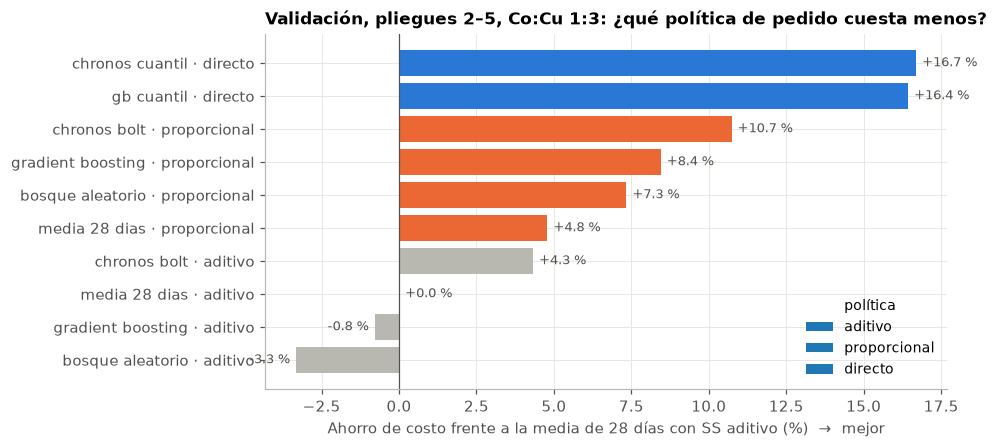

In [7]:
d = validacion[validacion['escenario'] == PRINCIPAL].assign(
    opcion=lambda t: t['modelo'] + ' · ' + t['politica']).sort_values('costo_vs_media28_pct')
colores_politica = {'aditivo': GRIS, 'proporcional': NARANJA, 'directo': AZUL}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(d['opcion'], d['costo_vs_media28_pct'], color=d['politica'].map(colores_politica))
for i, v in enumerate(d['costo_vs_media28_pct']):
    ax.annotate(f'{v:+.1f} %', (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                va='center', ha='left' if v >= 0 else 'right', fontsize=8.5, color=TINTA_2)
ax.axvline(0, color=TINTA_2, lw=0.8)
ax.set_xlabel('Ahorro de costo frente a la media de 28 días con SS aditivo (%)  →  mejor')
ax.set_title(f'Validación, pliegues 2–5, Co:Cu {PRINCIPAL}: ¿qué política de pedido cuesta menos?')
for tipo, color in colores_politica.items():
    ax.barh([], [], color=color, label=tipo)
ax.legend(frameon=False, fontsize=9, loc='lower right', title='política', title_fontsize=9)
fig.savefig(f'{FIGURAS}/negocio_validacion.png')
plt.show()

## 4. Champion y challenger por costo de validación

- **Champion:** la opción (modelo + política) con menor costo de validación en el escenario principal 1:3.
- **Challenger:** la mejor opción de **otra familia** de modelos. Si el champion falla en producción, conviene que el
  respaldo no comparta sus debilidades.

La comparación pareada pliegue a pliegue responde la pregunta del PDF: ¿la diferencia entre ganador y segundo supera la
variación entre pliegues?

In [8]:
ranking = validacion[validacion['escenario'] == PRINCIPAL].sort_values('costo').reset_index(drop=True)
campeon = ranking.iloc[0]
retador = ranking[ranking['modelo'].map(FAMILIA) != FAMILIA[campeon['modelo']]].iloc[0]
ELEGIDOS = {'champion': (campeon['modelo'], campeon['politica']),
            'challenger': (retador['modelo'], retador['politica'])}
for rol, (modelo, tipo) in ELEGIDOS.items():
    fila = ranking[(ranking['modelo'] == modelo) & (ranking['politica'] == tipo)].iloc[0]
    print(f'{rol:10s} {modelo} · {tipo}: costo {fila["costo"]:,.0f} ({fila["costo_vs_media28_pct"]:+.1f} % vs media 28) '
          f'· merma {fila["merma"]:.1%} · cobertura {fila["cobertura"]:.1%}')


def costo_por_pliegue(escenario, modelo, tipo):
    co, cu = ESCENARIOS[escenario]
    v = pedidos_validacion[(escenario, modelo, tipo)]
    return v.groupby('pliegue').apply(lambda g: resultado_negocio(g['y'], g['pedido'], co, cu)['costo'])


pareada = pd.DataFrame({
    escenario: 100 * (costo_por_pliegue(escenario, *ELEGIDOS['challenger'])
                      / costo_por_pliegue(escenario, *ELEGIDOS['champion']) - 1)
    for escenario in ESCENARIOS})
pareada.index = [f'pliegue {k}' for k in pareada.index]
print('\n¿Cuánto más cuesta el challenger que el champion en cada pliegue? (%, > 0: gana el champion)')
print(pareada.round(1).to_string())
print('Pliegues ganados por el champion:', (pareada > 0).sum().to_dict())

costo_champion = costo_por_pliegue(PRINCIPAL, *ELEGIDOS['champion'])
costo_media28 = costo_por_pliegue(PRINCIPAL, 'media 28 dias', 'aditivo')
ahorro = 100 * (1 - costo_champion / costo_media28)
print(f'\nAhorro del champion frente a la media 28 por pliegue ({PRINCIPAL}): {ahorro.round(1).to_list()} %')
comprobar(2, (ahorro > 0).all() and ELEGIDOS['champion'][1] == 'directo')

champion   chronos cuantil · directo: costo 783,723 (+16.7 % vs media 28) · merma 33.8% · cobertura 88.3%
challenger gb cuantil · directo: costo 786,147 (+16.4 % vs media 28) · merma 32.3% · cobertura 87.1%

¿Cuánto más cuesta el challenger que el champion en cada pliegue? (%, > 0: gana el champion)
              3:1    1:1     1:3
pliegue 2  4.7000 2.3000  1.2000
pliegue 3  2.4000 1.1000  0.2000
pliegue 4  1.6000 0.3000 -0.6000
pliegue 5 63.9000 1.5000  0.3000
Pliegues ganados por el champion: {'3:1': 4, '1:1': 4, '1:3': 3}

Ahorro del champion frente a la media 28 por pliegue (1:3): [16.7, 17.1, 17.9, 14.9] %
Comprobación 2: OK


**Corridas de los candidatos nuevos.** `gb cuantil` y `chronos cuantil` se registran en MLflow con `fase = candidato`
y `objetivo = negocio`, con las mismas métricas de validación que el resto: el costo, la merma y la cobertura de cada
escenario (pliegues 2–5), la pérdida de cuantil por pliegue y el tiempo. Así toda la historia de la selección queda en
el experimento.

In [9]:
for familia in CUANTILES:
    with mlflow.start_run(run_name=familia):
        mlflow.set_tags({'fase': 'candidato', 'objetivo': 'negocio', 'familia': FAMILIA[familia],
                         'politica': 'cuantil directo', 'git_commit': GIT_COMMIT,
                         'git_cambios_sin_commit': GIT_SUCIO, 'modelo_guardado': 'no'})
        base = HIPER_GB if familia == 'gb cuantil' else {k: v for k, v in chronos_ajustado.items() if k != 'cuantil'}
        mlflow.log_params({**DATOS, 'semilla': SEMILLA, 'cuantiles': '0.25, 0.5, 0.75',
                           'hiperparametros_de': 'tuning de ' + ('gradient boosting' if familia == 'gb cuantil'
                                                                 else 'chronos bolt'),
                           **{f'hp_{k}': v for k, v in base.items()}})
        metricas = {}
        for escenario in ESCENARIOS:
            fila = validacion[(validacion['escenario'] == escenario) & (validacion['modelo'] == familia)].iloc[0]
            sufijo = escenario.replace(':', '_')
            metricas.update({f'costo_val_{sufijo}': fila['costo'], f'merma_val_{sufijo}': fila['merma'],
                             f'cobertura_val_{sufijo}': fila['cobertura'],
                             f'costo_val_vs_media28_pct_{sufijo}': fila['costo_vs_media28_pct'],
                             f'segundos_cv_{sufijo}': segundos_oof[f'{familia} {cuantil_de(escenario)}']})
        mlflow.log_metrics(metricas)
        q = cuantil_de(PRINCIPAL)
        for k, g in oof[f'{familia} {q}'].groupby('pliegue'):
            mlflow.log_metric('perdida_cuantil_cv_pliegue', mean_pinball_loss(g['y'], g['pred'], alpha=q), step=k)
            mlflow.log_metric('rmsle_cv_pliegue', rmsle(g['y'], g['pred']), step=k)
        mlflow.log_text(validacion.to_csv(index=False), 'negocio/validacion_politicas.csv')
    print('corrida candidato:', familia)

🏃 View run gb cuantil at: http://127.0.0.1:5050/#/experiments/3/runs/1af451af89d346eea7e10d049754047a
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
corrida candidato: gb cuantil


🏃 View run chronos cuantil at: http://127.0.0.1:5050/#/experiments/3/runs/e87714d0fdb041e7a6cbff9044022fbb
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
corrida candidato: chronos cuantil


## 5. Prueba (una sola vez)

Cada opción se reentrena con todo el entrenamiento (hasta el 30/07/2017) y pide para los 16 días de prueba.

- **Champion y challenger:** cuantil directo, un modelo por escenario (q = 0,25; 0,50; 0,75).
- **Referencias:** la media de 28 días y la regla semanal con el SS aditivo (la regla del PSet 1), y el gradient
  boosting ajustado por RMSLE con su mejor política de validación, para mostrar el efecto del criterio.

El SS de las referencias se estima con los errores fuera de muestra de los 5 pliegues: nunca con la prueba.

In [10]:
oof['regla semanal'] = fuera_de_muestra(modelos['regla semanal'])
mejor_politica_gb = (validacion[(validacion['modelo'] == 'gradient boosting')]
                     .sort_values('costo').groupby('escenario')['politica'].first())
OPCIONES_PRUEBA = {
    'champion': ELEGIDOS['champion'], 'challenger': ELEGIDOS['challenger'],
    'gradient boosting (rmsle)': ('gradient boosting', None),
    'media 28 dias': ('media 28 dias', 'aditivo'), 'regla semanal': ('regla semanal', 'aditivo')}

finales_q, pronosticos, segundos_entrenamiento, segundos_inferencia = {}, {}, {}, {}
for etiqueta, (modelo, tipo) in OPCIONES_PRUEBA.items():
    for escenario in ESCENARIOS:
        q = cuantil_de(escenario)
        if modelo in CUANTILES:
            inicio = time.perf_counter()
            ajustado = CUANTILES[modelo](q).fit(X_ent, y_ent)
            segundos_entrenamiento[(etiqueta, escenario)] = time.perf_counter() - inicio
            finales_q[(etiqueta, escenario)] = ajustado
        else:
            ajustado = modelos[modelo]
        inicio = time.perf_counter()
        if modelo in CUANTILES or (etiqueta, 'pred') not in pronosticos:
            pred = np.clip(ajustado.predict(X_prueba), 0, None)
            segundos_inferencia[(etiqueta, escenario)] = time.perf_counter() - inicio
        if modelo in CUANTILES:
            pronosticos[(etiqueta, escenario)] = pred
        else:
            pronosticos[(etiqueta, 'pred')] = pred
    print(f'{etiqueta:26s} listo', flush=True)

filas, pedidos_prueba = [], {}
for etiqueta, (modelo, tipo) in OPCIONES_PRUEBA.items():
    for escenario, (co, cu) in ESCENARIOS.items():
        q = cuantil_de(escenario)
        politica = mejor_politica_gb[escenario] if tipo is None else tipo
        pred = pronosticos[(etiqueta, escenario)] if modelo in CUANTILES else pronosticos[(etiqueta, 'pred')]
        pedido = con_politica(pred, familias, oof[modelo] if modelo in oof else None, q, politica)
        pedidos_prueba[(etiqueta, escenario)] = pedido
        filas.append({'escenario': escenario, 'opcion': etiqueta, 'modelo': modelo, 'politica': politica,
                      **resultado_negocio(y_prueba, pedido, co, cu)})
negocio = pd.DataFrame(filas)
referencia = negocio[negocio['opcion'] == 'media 28 dias'].set_index('escenario')
negocio['costo_vs_media28_pct'] = 100 * (1 - negocio['costo'] / negocio['escenario'].map(referencia['costo']))
negocio['merma_vs_media28_pp'] = 100 * (negocio['merma'] - negocio['escenario'].map(referencia['merma']))
negocio['cobertura_vs_media28_pp'] = 100 * (negocio['cobertura'] - negocio['escenario'].map(referencia['cobertura']))

# Al subir q (faltar cuesta más) se pide más: cobertura y merma deben subir en todas las opciones.
tabla_q = negocio.assign(q=negocio['escenario'].map(cuantil_de)).pivot(
    index='opcion', columns='q', values=['cobertura', 'merma'])
monotona = pd.concat([tabla_q[m].diff(axis=1).iloc[:, 1:] for m in ['cobertura', 'merma']], axis=1)
comprobar(3, len(X_prueba) == meta['n_series'] * HORIZONTE and X_prueba['DATE'].min() > X_ent['DATE'].max()
          and (monotona > 0).all().all())

(negocio.sort_values(['escenario', 'costo'], key=lambda c: c.map({'1:3': 0, '1:1': 1, '3:1': 2}) if c.name == 'escenario' else c)
 .set_index(['escenario', 'opcion'])
 [['modelo', 'politica', 'merma', 'cobertura', 'costo', 'merma_vs_media28_pp', 'cobertura_vs_media28_pp',
   'costo_vs_media28_pct']]
 .style.format({'merma': '{:.1%}', 'cobertura': '{:.1%}', 'costo': '{:,.0f}', 'merma_vs_media28_pp': '{:+.1f}',
                'cobertura_vs_media28_pp': '{:+.1f}', 'costo_vs_media28_pct': '{:+.1f} %'}))

champion                   listo


challenger                 listo


gradient boosting (rmsle)  listo


media 28 dias              listo


regla semanal              listo


Comprobación 3: revisa


**Lectura.** Si el GB-cuantil aparece en 3:1 con cobertura 0 %, no es un error de cálculo: con q = 0,25 la pérdida de
cuantil de `HistGradientBoostingRegressor` colapsa a pedir 0 en todas las series. Más de un cuarto de las filas
vende 0, así que el cuantil 0,25 inicial es 0 y los gradientes no lo sacan de ahí. Ya se veía en la validación (el
pliegue 5 de 3:1 le cuesta un 64 % más que a Chronos). El escenario principal (1:3) y el champion no dependen de esto,
pero es una razón más para no usar el GB-cuantil cuando sobrar cuesta más que faltar.

**Métrica técnica en la prueba.** El RMSLE mide qué tan cerca queda el pronóstico de la venta. Un pronóstico del
cuantil 0,75 está **a propósito** por encima de la mediana, así que su RMSLE es peor que el del modelo ajustado por
RMSLE. No es un defecto: es el precio de pedir de más cuando faltar cuesta el triple. Se reportan los dos, cada uno con
lo que mide.

In [11]:
q_principal = cuantil_de(PRINCIPAL)
tecnica = {}
for etiqueta, (modelo, tipo) in OPCIONES_PRUEBA.items():
    pred = pronosticos[(etiqueta, PRINCIPAL)] if modelo in CUANTILES else pronosticos[(etiqueta, 'pred')]
    tecnica[etiqueta] = {'rmsle_prueba': rmsle(y_prueba, pred), 'mae_prueba': mean_absolute_error(y_prueba, pred),
                         'sesgo_prueba': sesgo(y_prueba, pred),
                         'perdida_cuantil_prueba': mean_pinball_loss(y_prueba, pred, alpha=q_principal)}
for etiqueta in ['champion', 'challenger']:          # la mediana de la misma familia, como referencia técnica
    tecnica[f'{etiqueta} (q = 0,5)'] = {'rmsle_prueba': rmsle(y_prueba, pronosticos[(etiqueta, '1:1')]),
                                        'mae_prueba': mean_absolute_error(y_prueba, pronosticos[(etiqueta, '1:1')]),
                                        'sesgo_prueba': sesgo(y_prueba, pronosticos[(etiqueta, '1:1')]),
                                        'perdida_cuantil_prueba': np.nan}
tecnica = pd.DataFrame(tecnica).T
tecnica['rmsle_cv'] = [cv[m].mean() if m in cv else np.nan
                       for m in [OPCIONES_PRUEBA.get(e, (None,))[0] for e in tecnica.index]]
tecnica.sort_values('perdida_cuantil_prueba')

,rmsle_prueba,mae_prueba,sesgo_prueba,perdida_cuantil_prueba,rmsle_cv
champion,0.7828,4.1620,2.5690,1.4388,NaN
challenger,0.8079,4.2081,2.5554,1.4652,NaN
media 28 dias,0.6844,3.4689,0.1616,1.6940,0.7231
gradient boosting (rmsle),0.6477,3.2763,-1.0311,1.8959,0.6697
regla semanal,0.8414,4.0380,-0.1425,2.0546,0.8505
"champion (q = 0,5)",0.6517,3.1609,-0.5198,NaN,NaN
"challenger (q = 0,5)",0.6642,3.2377,-0.3045,NaN,NaN


In [12]:
# Costo en 1:3 por familia: ¿el champion gana en todas las familias o solo en el total?
co, cu = ESCENARIOS[PRINCIPAL]
filas = []
for f in np.unique(familias):
    m = familias == f
    for etiqueta in ['media 28 dias', 'champion', 'challenger']:
        r = resultado_negocio(y_prueba[m], pedidos_prueba[(etiqueta, PRINCIPAL)][m], co, cu)
        filas.append({'familia': f, 'opcion': etiqueta, 'merma': r['merma'], 'cobertura': r['cobertura'],
                      'costo': r['costo']})
por_familia_negocio = pd.DataFrame(filas).pivot(index='familia', columns='opcion')
for etiqueta in ['champion', 'challenger']:
    por_familia_negocio[('ahorro_vs_media28_pct', etiqueta)] = 100 * (
        1 - por_familia_negocio[('costo', etiqueta)] / por_familia_negocio[('costo', 'media 28 dias')])
por_familia_negocio = por_familia_negocio.sort_values(('costo', 'media 28 dias'), ascending=False)
por_familia_negocio.style.format('{:.1%}', subset=['merma', 'cobertura']).format(
    '{:,.0f}', subset=['costo']).format('{:+.1f} %', subset=['ahorro_vs_media28_pct'])

**Frontera merma–cobertura.** Al recorrer q de 0,05 a 0,95 con el SS aditivo se traza el intercambio completo de la
media de 28 días y del GB por RMSLE. Los cuantiles directos aparecen como puntos (uno por escenario). Un mejor pedido
queda **abajo y a la derecha**: la misma cobertura con menos merma.

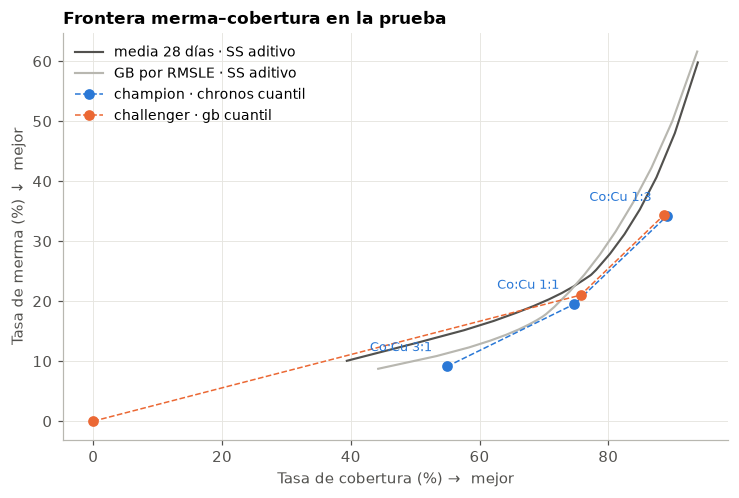

In [13]:
cuantiles = np.round(np.arange(0.05, 0.96, 0.05), 2)
frontera = pd.DataFrame([
    {'opcion': n, 'q': q, **resultado_negocio(y_prueba, con_politica(pronosticos[(n, 'pred')], familias, oof[m], q,
                                                                        'aditivo'), 1, 1)}
    for n, m in [('media 28 dias', 'media 28 dias'), ('gradient boosting (rmsle)', 'gradient boosting')]
    for q in cuantiles])

colores = {'media 28 dias': TINTA_2, 'gradient boosting (rmsle)': GRIS, 'champion': AZUL, 'challenger': NARANJA}
nombres = {'champion': f'champion · {ELEGIDOS["champion"][0]}', 'challenger': f'challenger · {ELEGIDOS["challenger"][0]}',
           'media 28 dias': 'media 28 días · SS aditivo', 'gradient boosting (rmsle)': 'GB por RMSLE · SS aditivo'}
fig, ax = plt.subplots(figsize=(7.8, 4.8))
for n in ['media 28 dias', 'gradient boosting (rmsle)']:
    d = frontera[frontera['opcion'] == n]
    ax.plot(100 * d['cobertura'], 100 * d['merma'], '-', color=colores[n], lw=1.4, label=nombres[n])
for n in ['champion', 'challenger']:
    d = negocio[negocio['opcion'] == n].assign(q=lambda t: t['escenario'].map(cuantil_de)).sort_values('q')
    ax.plot(100 * d['cobertura'], 100 * d['merma'], 'o--', color=colores[n], lw=1, ms=6, label=nombres[n])
    if n == 'champion':
        for _, fila in d.iterrows():
            ax.annotate(f"Co:Cu {fila['escenario']}", (100 * fila['cobertura'], 100 * fila['merma']),
                        xytext=(-10, 10), textcoords='offset points', ha='right', fontsize=8.5, color=AZUL)
ax.set_xlabel('Tasa de cobertura (%) →  mejor')
ax.set_ylabel('Tasa de merma (%) ↓  mejor')
ax.set_title('Frontera merma–cobertura en la prueba')
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.savefig(f'{FIGURAS}/negocio_frontera.png')
plt.show()

## 6. Costo y explicabilidad

In [14]:
def tamano_artefacto(run_id, ruta='modelo'):
    total = 0
    for archivo in cliente.list_artifacts(run_id, ruta):
        total += tamano_artefacto(run_id, archivo.path) if archivo.is_dir else (archivo.file_size or 0)
    return total


costos = pd.DataFrame({
    etiqueta: {'modelo': ELEGIDOS[etiqueta][0],
               'segundos_entrenamiento': segundos_entrenamiento[(etiqueta, PRINCIPAL)],
               'segundos_inferencia_prueba': segundos_inferencia[(etiqueta, PRINCIPAL)],
               'segundos_cv_5_pliegues': segundos_oof[f'{ELEGIDOS[etiqueta][0]} {q_principal}']}
    for etiqueta in ['champion', 'challenger']}).T
costos

,modelo,segundos_entrenamiento,segundos_inferencia_prueba,segundos_cv_5_pliegues
champion,chronos cuantil,0.2345,13.0881,59.5461
challenger,gb cuantil,149.5932,0.6489,701.0112


**Explicabilidad.** El GB-cuantil se explica con la **importancia por permutación** en la prueba: se desordena una
variable a la vez y se mide cuánto sube la pérdida de cuantil 0,75, que es el costo del escenario principal salvo una
constante (5 repeticiones, sobre las columnas originales). Chronos no tiene un equivalente: su único insumo es la
historia de ventas de cada serie, y su razonamiento ocurre dentro de una red preentrenada. Lo que se puede decir de él
es qué ve (los últimos días de venta, en la escala y el contexto ajustados) y cómo se comporta (costo y sesgo por
familia, en §5).

Permutación: 112 s


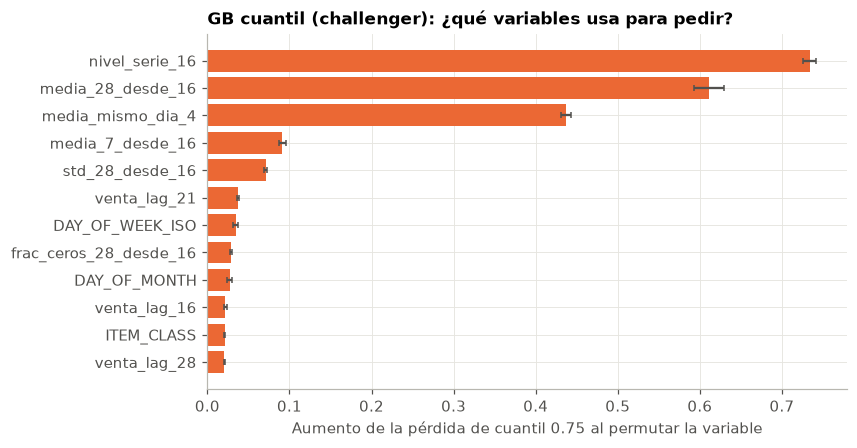

,variable,aumento_perdida,desviacion
11,nivel_serie_16,0.7337,0.0081
7,media_28_desde_16,0.6112,0.0184
5,media_mismo_dia_4,0.4373,0.0059
6,media_7_desde_16,0.0915,0.0039
8,std_28_desde_16,0.0713,0.0018
1,venta_lag_21,0.0379,0.0013
23,DAY_OF_WEEK_ISO,0.0344,0.0030
9,frac_ceros_28_desde_16,0.0287,0.0015
13,DAY_OF_MONTH,0.0270,0.0034
0,venta_lag_16,0.0219,0.0021


In [15]:
etiqueta_gb = next(e for e in ['champion', 'challenger'] if ELEGIDOS[e][0] == 'gb cuantil')
modelo_gb = finales_q[(etiqueta_gb, PRINCIPAL)]
variables = NUMERICAS + YA_LISTAS + CATEGORICAS
inicio = time.perf_counter()
importancia = permutation_importance(
    modelo_gb, X_prueba, y_prueba, n_repeats=5, random_state=SEMILLA,
    scoring=make_scorer(mean_pinball_loss, alpha=q_principal, greater_is_better=False))
importancias = (pd.DataFrame({'variable': X_prueba.columns, 'aumento_perdida': importancia.importances_mean,
                              'desviacion': importancia.importances_std})
                .query('variable in @variables').sort_values('aumento_perdida', ascending=False))
print(f'Permutación: {time.perf_counter() - inicio:.0f} s')

principales = importancias.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(principales['variable'], principales['aumento_perdida'], xerr=principales['desviacion'], color=NARANJA,
        ecolor=TINTA_2, capsize=2)
ax.set_xlabel(f'Aumento de la pérdida de cuantil {q_principal} al permutar la variable')
ax.set_title(f'GB cuantil ({etiqueta_gb}): ¿qué variables usa para pedir?')
fig.savefig(f'{FIGURAS}/importancia_gb_cuantil.png')
plt.show()
importancias.head(12)

## 7. Corridas finales y Model Registry

- **champion** y **challenger**: el pipeline de cuantil 0,75 (escenario principal 1:3) reentrenado con todo el
  entrenamiento. Su salida **es el pedido sugerido** por tienda–producto–día. Se registran en
  `favorita-perecederos-modelo` con los alias `champion` y `challenger`.
- **referencia**: la media de 28 días, la regla semanal y el GB por RMSLE, con las mismas métricas para comparar.

Las métricas de negocio de cada escenario se registran como `costo_1_3`, `merma_1_3`, `cobertura_1_3`, etc. (prueba) y
`costo_val_1_3`, etc. (validación). El RMSLE de prueba también se registra: el notebook 06 lo reproduce.

In [16]:
ROLES = {'champion': 'champion', 'challenger': 'challenger', 'gradient boosting (rmsle)': 'referencia',
         'media 28 dias': 'referencia', 'regla semanal': 'referencia'}
finales = {}
for etiqueta, (modelo, tipo) in OPCIONES_PRUEBA.items():
    rol = ROLES[etiqueta]
    guardado = finales_q[(etiqueta, PRINCIPAL)] if modelo in CUANTILES else modelos[modelo]
    nombre_corrida = f'final {modelo}' if modelo in CUANTILES else f'final {etiqueta}'
    with mlflow.start_run(run_name=nombre_corrida) as corrida:
        politica_principal = negocio[(negocio['opcion'] == etiqueta) & (negocio['escenario'] == PRINCIPAL)]['politica'].iloc[0]
        mlflow.set_tags({'fase': 'final', 'rol': rol, 'familia': FAMILIA[modelo], 'politica': politica_principal,
                         'escenario_principal': PRINCIPAL, 'criterio_seleccion': 'costo de negocio en validacion',
                         'git_commit': GIT_COMMIT, 'git_cambios_sin_commit': GIT_SUCIO, 'modelo_guardado': 'si'})
        parametros = {**DATOS, 'semilla': SEMILLA, 'modelo': modelo}
        if modelo in CUANTILES:
            parametros.update({'cuantil': q_principal, 'hiperparametros_de': origen[
                'gradient boosting' if modelo == 'gb cuantil' else 'chronos bolt']})
        elif modelo in origen:
            parametros['run_id_origen'] = origen[modelo]
        mlflow.log_params(parametros)

        metricas = tecnica.loc[etiqueta].dropna().to_dict()
        if modelo in cv:
            metricas.update({'rmsle_cv': cv[modelo].mean(), 'rmsle_cv_std': cv[modelo].std(ddof=0)})
        if (etiqueta, PRINCIPAL) in segundos_entrenamiento:
            metricas['segundos'] = segundos_entrenamiento[(etiqueta, PRINCIPAL)]
        if (etiqueta, PRINCIPAL) in segundos_inferencia:
            metricas['segundos_inferencia_prueba'] = segundos_inferencia[(etiqueta, PRINCIPAL)]
        for _, fila in negocio[negocio['opcion'] == etiqueta].iterrows():
            sufijo = fila['escenario'].replace(':', '_')
            metricas.update({f'merma_{sufijo}': fila['merma'], f'cobertura_{sufijo}': fila['cobertura'],
                             f'costo_{sufijo}': fila['costo'],
                             f'costo_vs_media28_pct_{sufijo}': fila['costo_vs_media28_pct']})
            val = validacion[(validacion['escenario'] == fila['escenario']) & (validacion['modelo'] == fila['modelo'])
                             & (validacion['politica'] == fila['politica'])]
            if len(val):
                metricas.update({f'costo_val_{sufijo}': val['costo'].iloc[0],
                                 f'costo_val_vs_media28_pct_{sufijo}': val['costo_vs_media28_pct'].iloc[0]})
        mlflow.log_metrics(metricas)

        info = mlflow.sklearn.log_model(guardado, name='modelo', input_example=ejemplo,
                                        signature=infer_signature(ejemplo, guardado.predict(ejemplo)),
                                        code_paths=['../src'], skops_trusted_types=CONFIABLES)
        if rol == 'champion':
            for figura in ['negocio_validacion.png', 'negocio_frontera.png', 'importancia_gb_cuantil.png']:
                mlflow.log_artifact(f'{FIGURAS}/{figura}', 'figuras')
            mlflow.log_text(validacion.to_csv(index=False), 'negocio/validacion_politicas.csv')
            mlflow.log_text(negocio.to_csv(index=False), 'negocio/prueba_escenarios.csv')
            mlflow.log_text(frontera.to_csv(index=False), 'negocio/frontera.csv')
            mlflow.log_text(por_familia_negocio.to_csv(), 'negocio/prueba_por_familia_1_3.csv')
        if modelo == 'gb cuantil':
            mlflow.log_text(importancias.to_csv(index=False), 'explicabilidad/importancia_permutacion.csv')
    finales[etiqueta] = {'run_id': corrida.info.run_id, 'model_uri': info.model_uri, 'rol': rol, 'modelo': modelo}
    print(f'{rol:10s} {etiqueta:26s} run_id {corrida.info.run_id}')

🏃 View run final chronos cuantil at: http://127.0.0.1:5050/#/experiments/3/runs/bc9d609b18d442178bcd1482792c295b
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
champion   champion                   run_id bc9d609b18d442178bcd1482792c295b


🏃 View run final gb cuantil at: http://127.0.0.1:5050/#/experiments/3/runs/92e6ab324b6c44bea6f07da4b15e960e
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
challenger challenger                 run_id 92e6ab324b6c44bea6f07da4b15e960e


🏃 View run final gradient boosting (rmsle) at: http://127.0.0.1:5050/#/experiments/3/runs/d52ac10a64014308a5a7be74d013fe5c
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
referencia gradient boosting (rmsle)  run_id d52ac10a64014308a5a7be74d013fe5c


🏃 View run final media 28 dias at: http://127.0.0.1:5050/#/experiments/3/runs/3df26f4c45864cc5bd6d1745ada8ae4b
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
referencia media 28 dias              run_id 3df26f4c45864cc5bd6d1745ada8ae4b


🏃 View run final regla semanal at: http://127.0.0.1:5050/#/experiments/3/runs/26d008de2df4423191a2eda950c87c60
🧪 View experiment at: http://127.0.0.1:5050/#/experiments/3
referencia regla semanal              run_id 26d008de2df4423191a2eda950c87c60


In [17]:
versiones = {}
for etiqueta in ['champion', 'challenger']:
    final = finales[etiqueta]
    fila = negocio[(negocio['opcion'] == etiqueta) & (negocio['escenario'] == PRINCIPAL)].iloc[0]
    version = mlflow.register_model(final['model_uri'], MODELO_REGISTRADO,
                                    tags={'rol': etiqueta, 'run_id': final['run_id'], 'modelo': final['modelo'],
                                          'cuantil': str(q_principal), 'escenario': PRINCIPAL})
    cliente.set_registered_model_alias(MODELO_REGISTRADO, etiqueta, version.version)
    cliente.update_model_version(
        MODELO_REGISTRADO, version.version,
        description=(f"{final['modelo']} q={q_principal} ({etiqueta}). Pedido sugerido para Co:Cu {PRINCIPAL}. "
                     f"Prueba: costo {fila['costo']:,.0f} ({fila['costo_vs_media28_pct']:+.1f} % vs media 28 días), "
                     f"merma {fila['merma']:.1%}, cobertura {fila['cobertura']:.1%}, "
                     f"RMSLE {tecnica.loc[etiqueta, 'rmsle_prueba']:.4f}. Corrida final {final['run_id']}."))
    versiones[etiqueta] = version.version

cliente.update_registered_model(
    MODELO_REGISTRADO,
    description='Pedido sugerido (cuantil 0,75 de la venta diaria) de perecederos por tienda–producto, horizonte de '
                '16 días (Corporación Favorita), para Co:Cu = 1:3. Elegido por costo de negocio en validación. '
                'Entrada: features de src/pipeline.py; salida: unidades (≥ 0).')

for alias in ['champion', 'challenger']:
    v = cliente.get_model_version_by_alias(MODELO_REGISTRADO, alias)
    print(f'{MODELO_REGISTRADO}@{alias}: versión {v.version} · run_id {v.run_id} · {v.tags.get("modelo")}')
comprobar(4, cliente.get_model_version_by_alias(MODELO_REGISTRADO, 'champion').run_id == finales['champion']['run_id'])

Registered model 'favorita-perecederos-modelo' already exists. Creating a new version of this model...


Created version '3' of model 'favorita-perecederos-modelo'.


Registered model 'favorita-perecederos-modelo' already exists. Creating a new version of this model...
Created version '4' of model 'favorita-perecederos-modelo'.


favorita-perecederos-modelo@champion: versión 3 · run_id bc9d609b18d442178bcd1482792c295b · chronos cuantil
favorita-perecederos-modelo@challenger: versión 4 · run_id 92e6ab324b6c44bea6f07da4b15e960e · gb cuantil
Comprobación 4: OK


## 8. Exportar las corridas a `docs/corridas.csv`

In [18]:
corridas = mlflow.search_runs(experiment_names=[EXPERIMENTO], max_results=50_000)
corridas.to_csv('../docs/corridas.csv', index=False)

conteo = corridas['tags.fase'].value_counts()
hijas = corridas['tags.mlflow.parentRunId'].notna().sum() if 'tags.mlflow.parentRunId' in corridas else 0
print(f'{len(corridas)} corridas exportadas · {hijas} hijas de tuning')
print(conteo.to_string())
minimos = {'baseline': 2, 'candidato': 7, 'tuning': 93, 'final': 2}    # candidato: 5 del nb 03 + 2 de cuantil
comprobar(5, all(conteo.get(fase, 0) >= n for fase, n in minimos.items()) and hijas >= 90)

113 corridas exportadas · 90 hijas de tuning
tags.fase
tuning       93
final         9
candidato     8
baseline      3
Comprobación 5: OK


## 9. Conclusiones

| | Validación (pliegues 2–5), 1:3 | Prueba, 1:3 | RMSLE prueba |
|---|---|---|---|
| **Champion: Chronos-Bolt cuantil 0,75** | −16,7 % de costo vs media 28 | **−12,0 %** · merma 34,2 % · cobertura 89,1 % | 0,783 |
| **Challenger: GB-cuantil 0,75** | −16,4 % | −10,4 % · merma 34,4 % · cobertura 88,7 % | 0,808 |
| GB por RMSLE (mejor política) | −8,4 % | −0,4 % | **0,648** |
| Media 28 días + SS aditivo | — | 209.373 · merma 31,2 % · cobertura 82,5 % | 0,684 |

1. **Pedir el cuantil es la política correcta.** Con el costo *newsvendor*, pronosticar directamente el cuantil
   q = Cu/(Cu+Co) le gana a sumar un stock de seguridad, aditivo o proporcional, en todos los modelos y escenarios
   salvo el GB-cuantil en 3:1.
2. **El mejor RMSLE no es el mejor negocio.** El GB elegido por RMSLE empata en costo con la media de 28 días. El
   champion tiene peor RMSLE (pide de más a propósito), pero sube la cobertura 6,5 pp a cambio de 3,0 pp de merma.
   Con un faltante que cuesta el triple, eso ahorra un 12 %.
3. **La selección se sostiene fuera de muestra.** El orden de la validación se repite en la prueba, y el champion le
   gana a la media de 28 días en las 9 familias.
4. **Champion y challenger están muy cerca en 1:3** (0,3 % en validación; Chronos gana 3 de 4 pliegues). Chronos es
   más robusto en los otros escenarios. El GB-cuantil colapsa con q = 0,25. Pero el GB-cuantil es explicable y su
   inferencia es 20 veces más rápida, por eso es el respaldo.
5. **Limitaciones.** El SS y las políticas se estimaron con 4 pliegues de 16 días. Chronos no usa covariables
   (promociones, feriados): Chronos-2, que sí las admite, queda como trabajo futuro. Los costos Co:Cu son supuestos de
   escenario, no costos contables de Favorita.